[Don't change markdown blocks in this file with AI.]

This part of code investigates how a language model answers questions with insufficient context.

# Part 1. Autorater

Use Qwen3.8-27B (0-shot), Qwen3.8-27B (1-shot) and TRUE-NLI as autorater，SufficiencyBench v1.1 as dataset.

| Methods | F1 Score | Accuracy | Precision | Recall | GT Answer |
|:---|---:|---:|---:|---:|:---:|
| Qwen3.8-27B (1-shot, 4-bit) | **0.8657** | **0.8561** | 0.8113 | **0.9280** | ✗ |
| Qwen3.8-27B (0-shot, 4-bit) | 0.8319 | 0.8163 | 0.7668 | 0.9091 | ✗ |
| TRUE-NLI (T5 11B, INT8) | 0.8317 | 0.8390 | **0.8714** | 0.7955 | ✓ |

Choose Qwen3.8-27B (1-shot, 4-bit) as autorater.

code in src/autorater

# Part 2. Evaluate RAG when given sufficient / insufficient information

## (a) Use the autorater to prepare dataset
虽然在训练autorater时用了有标注sufficient / insufficient的dataset，但那是人工去掉了关键信息的而且上下文长度太小(<1000 token)。通过在MuSiQue上截取固定数量的段落，然后用autorater判断sufficient / insufficient，能更好地模拟RAG的实际输入上下文。

code in src/musique

## (b) Evaluation

Certain results may not look good because (1) we are using small language models (2) we deliberately choose multi-hop questions, which are tricky to answer.

code in src/rag_behavior


/mnt/e/university_file/SC4001/project/results/rag_behavior/musique_valid_no_abstain_hint/response_categories_pies.png


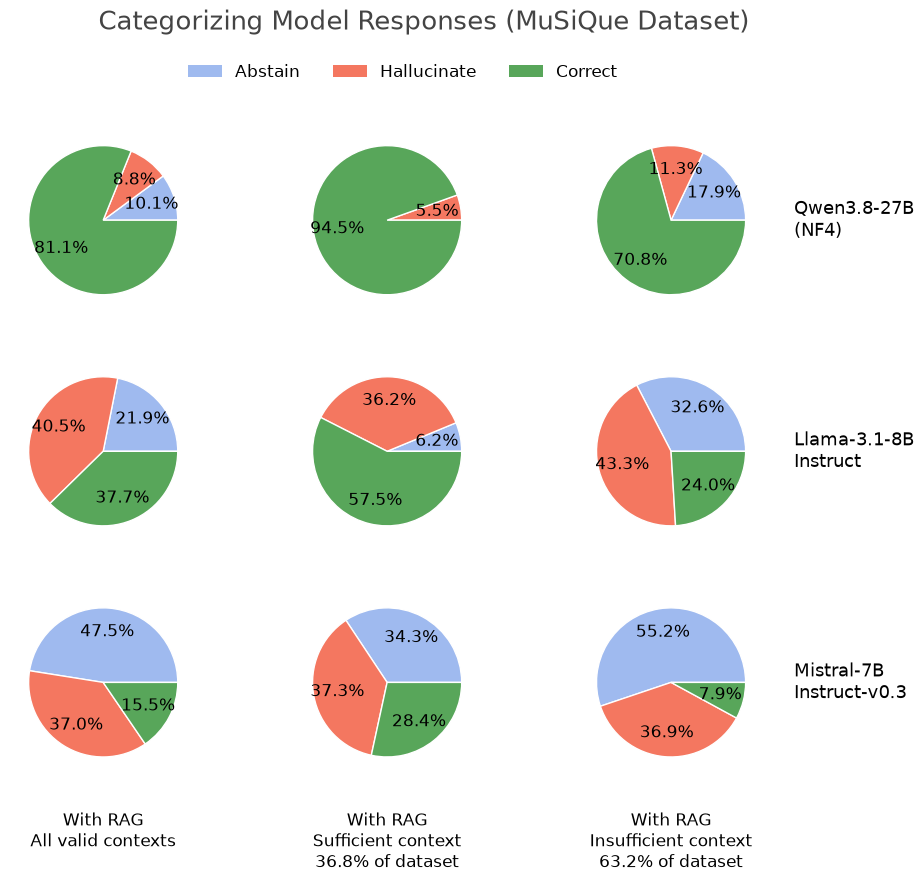

In [2]:
from pathlib import Path
import csv

# Works when the notebook is opened from either the project root or src/.
project_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src/rag_behavior").is_dir() and (p / "results").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open this notebook from the project directory or src/.")

results_dir = project_root / "results/rag_behavior/musique_valid_no_abstain_hint"
# Plot classified answers from the current partial results.
allow_partial = True

with (results_dir / 'metrics.csv').open(encoding='utf-8-sig', newline='') as stream:
    rows = list(csv.DictReader(stream))
names = [('qwen38', 'Qwen3.8-27B\n(NF4)'), ('llama31', 'Llama-3.1-8B\nInstruct'),
         ('mistral', 'Mistral-7B\nInstruct-v0.3')]
groups = ['all', 'sufficient', 'insufficient']
lookup = {(r['model'], r['context_group']): r for r in rows}
selected = [lookup[name, group] for name, _ in names for group in groups]
partial = any(int(r['unclassified']) for r in selected)
if partial and not allow_partial:
    raise ValueError('Incomplete results: pass --allow-partial to plot classified answers only.')
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12, 'pdf.fonttype': 42, 'svg.fonttype': 'none'})
colors = ['#9FBAEF', '#F47760', '#58A65A']
categories = ['abstain', 'hallucinate', 'correct']
fig, axes = plt.subplots(3, 3, figsize=(10.5, 9.4))
fig.subplots_adjust(left=.04, right=.81, bottom=.15, top=.84, wspace=.18, hspace=.24)
fig.suptitle('Categorizing Model Responses (MuSiQue Dataset)', x=.46, y=.965, fontsize=19, color='#444444')
fig.legend(handles=[Patch(facecolor=c, label=l) for c, l in zip(colors, ['Abstain', 'Hallucinate', 'Correct'])],
           loc='upper center', bbox_to_anchor=(.44, .923), ncol=3, frameon=False, columnspacing=2)
for i, (name, title) in enumerate(names):
    for k, group in enumerate(groups):
        row = lookup[name, group]
        values = [int(row[c]) for c in categories]
        if not sum(values):
            raise ValueError(f'No classified answers: {name}/{group}')
        axes[i, k].pie(values, colors=colors, startangle=0, counterclock=True,
                       autopct=lambda pct: f'{pct:.1f}%' if pct > .01 else '', pctdistance=.68,
                       textprops={'fontsize': 12}, wedgeprops={'linewidth': 1, 'edgecolor': 'white'})
        axes[i, k].set_aspect('equal')
    axes[i, -1].text(1.16, .5, title, transform=axes[i, -1].transAxes, ha='left', va='center', fontsize=13)
total = int(lookup['qwen38', 'all']['total'])
labels = ['With RAG\nAll valid contexts',
          f'With RAG\nSufficient context\n{int(lookup["qwen38", "sufficient"]["total"])/total:.1%} of dataset',
          f'With RAG\nInsufficient context\n{int(lookup["qwen38", "insufficient"]["total"])/total:.1%} of dataset']
for k, label in enumerate(labels):
    position = axes[-1, k].get_position()
    fig.text((position.x0 + position.x1)/2, .115, label, ha='center', va='top', fontsize=12, linespacing=1.25)
target = results_dir / 'response_categories_pies.png'
fig.savefig(target, dpi=240, bbox_inches='tight', facecolor='white')
print(target)
plt.show(fig)


# Part3 Implement baseline

论文第五节